<a href="https://colab.research.google.com/github/heloisafrancops-collab/Inteligencia-Artificial1/blob/main/Atividade_AutoML_Helo%C3%ADsa_Franco_6%C2%B0D_Matutino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparação de AutoML (FLAML vs. Auto-Sklearn) com o Dataset Iris

# Etapa 1 — Instalação do Pyenv

Instalamos o Pyenv para gerenciar diferentes versões do Python e preparar um ambiente compatível com o Auto-Sklearn.

In [17]:
# Instala as dependências para preparar outra versão do Python.
!apt-get update -qq
!apt-get install -y -qq build-essential libssl-dev zlib1g-dev \
libbz2-dev libreadline-dev libsqlite3-dev libffi-dev liblzma-dev

# Instala o pyenv.
!curl -fsSL https://pyenv.run | bash

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)




# Etapa 2 — Instalação do Python 3.9

Instalamos o Python 3.9.21 para executar o Auto-Sklearn sem alterar a versão principal do Google Colab.

In [18]:
# Instala o Python 3.9 pelo pyenv.
!/root/.pyenv/bin/pyenv install -s 3.9.21

-> https://www.python.org/ftp/python/3.9.21/Python-3.9.21.tar.xz
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 18.7M  100 18.7M    0     0  77.3M      0 --:--:-- --:--:-- --:--:-- 77.4M
Installing Python-3.9.21...
Installed Python-3.9.21 to /root/.pyenv/versions/3.9.21


# Etapa 3 — Verificação da versão do Python

Verificamos se o Python 3.9.21 foi instalado corretamente e está disponível para utilização.

In [19]:
# Verifica se o Python 3.9 foi instalado.
!/root/.pyenv/versions/3.9.21/bin/python --version

Python 3.9.21


# Etapa 4 — Instalação do FLAML

Instalamos o FLAML, ferramenta de AutoML utilizada para buscar automaticamente modelos de aprendizado de máquina.

In [20]:
# Instala o FLAML.
%pip install "flaml[automl]"

# Etapa 5 — Instalação do Auto-Sklearn

Instalamos o Auto-Sklearn no ambiente Python 3.9 para realizar a comparação com o FLAML.

In [21]:
# Instala o Auto-Sklearn no Python 3.9.
!/root/.pyenv/versions/3.9.21/bin/python -m pip install auto-sklearn==0.15.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 16.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 23.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 33.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 19.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.8/750.8 kB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.9/260.9 kB 16.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 36.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━

# Etapa 6 — Ajuste de compatibilidade do NumPy

Ajustamos a versão do NumPy para corrigir um conflito de compatibilidade com as dependências do Auto-Sklearn.

In [22]:
# Corrige a versão do NumPy no Python 3.9.
!/root/.pyenv/versions/3.9.21/bin/python -m pip install --force-reinstall "numpy==1.23.5"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 17.6 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2


# Etapa 7 — Verificação do Auto-Sklearn

Testamos a importação do Auto-Sklearn para confirmar que a biblioteca está funcionando corretamente.

In [23]:
# Testa o Auto-Sklearn usando o Python 3.9.
!/root/.pyenv/versions/3.9.21/bin/python -c "from autosklearn.classification import AutoSklearnClassifier; print('Auto-Sklearn importado com sucesso!')"

Auto-Sklearn importado com sucesso!


# Etapa 8 — Carregamento e preparação do dataset Iris
Explicação: Carregamos o dataset Iris, que contém 150 amostras de flores. Em seguida, dividimos os dados em 80% para treinamento e 20% para teste, mantendo a proporção das classes. Também salvamos os dados para utilizar nos dois frameworks.

In [24]:

# Importa as bibliotecas necessárias.
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Carrega o dataset Iris.
iris = load_iris()

# Separa os atributos e as classes.
X = iris.data
y = iris.target

# Divide os dados em treino e teste.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Salva os dados para utilizar nos dois ambientes Python.
np.savez(
    "/content/iris_dados.npz",
    X_treino=X_treino,
    X_teste=X_teste,
    y_treino=y_treino,
    y_teste=y_teste
)

# Mostra as informações do dataset.
print("=" * 45)
print("PREPARAÇÃO DO DATASET IRIS")
print("=" * 45)

print("Total de amostras:", len(X))
print("Amostras de treinamento:", len(X_treino))
print("Amostras de teste:", len(X_teste))
print("Espécies:", ", ".join(iris.target_names))

print("=" * 45)


PREPARAÇÃO DO DATASET IRIS
Total de amostras: 150
Amostras de treinamento: 120
Amostras de teste: 30
Espécies: setosa, versicolor, virginica


# Etapa 9 — Treinamento e avaliação com FLAML
Explicação: Treinamos o FLAML utilizando um orçamento de 60 segundos. Depois, calculamos a acurácia, medimos o tempo real de execução e mostramos o algoritmo selecionado e o relatório de classificação.

In [25]:

# Importa as bibliotecas necessárias.
import time
from flaml import AutoML
from sklearn.metrics import accuracy_score, classification_report

# Define o tempo de busca.
tempo_limite = 60

# Cria o modelo FLAML.
modelo_flaml = AutoML()

# Inicia a contagem do tempo.
inicio_flaml = time.time()

# Treina o modelo automaticamente.
modelo_flaml.fit(
    X_train=X_treino,
    y_train=y_treino,
    task="classification",
    metric="accuracy",
    time_budget=tempo_limite,
    seed=42,
    n_jobs=1,
    verbose=0
)

# Calcula o tempo real de execução.
tempo_flaml = time.time() - inicio_flaml

# Realiza as previsões.
previsoes_flaml = modelo_flaml.predict(X_teste)

# Calcula a acurácia.
acuracia_flaml = accuracy_score(y_teste, previsoes_flaml)

# Exibe os resultados.
print("=" * 50)
print("RESULTADOS DO FLAML")
print("=" * 50)

print(f"Acurácia: {acuracia_flaml:.2%}")
print(f"Tempo de execução: {tempo_flaml:.2f} segundos")
print("Melhor algoritmo:", modelo_flaml.best_estimator)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("-" * 50)

print(classification_report(
    y_teste,
    previsoes_flaml,
    target_names=iris.target_names,
    zero_division=0
))

print("=" * 50)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

RESULTADOS DO FLAML
Acurácia: 100.00%
Tempo de execução: 60.03 segundos
Melhor algoritmo: lrl1

RELATÓRIO DE CLASSIFICAÇÃO
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



# Etapa 10 — Treinamento e avaliação com Auto-Sklearn
Explicação: Vamos treinar o Auto-Sklearn com os mesmos dados utilizados pelo FLAML e o mesmo orçamento de 60 segundos. Depois, calcularemos a acurácia, o tempo de execução e o relatório de classificação.

In [26]:
# Verifica se o Pyenv ainda está instalado.
!/root/.pyenv/bin/pyenv versions

* system (set by /root/.pyenv/version)
  3.9.21


In [27]:

%%writefile /content/treinar_autosklearn.py

# Importa as bibliotecas necessárias.
import time
import json
import numpy as np
from autosklearn.classification import AutoSklearnClassifier
from sklearn.metrics import accuracy_score, classification_report

# Carrega os mesmos dados utilizados pelo FLAML.
dados = np.load("/content/iris_dados.npz")

X_treino = dados["X_treino"]
X_teste = dados["X_teste"]
y_treino = dados["y_treino"]
y_teste = dados["y_teste"]

# Cria o modelo Auto-Sklearn.
modelo_auto = AutoSklearnClassifier(
    time_left_for_this_task=60,
    per_run_time_limit=30,
    seed=42,
    n_jobs=1,
    memory_limit=3072
)

# Inicia a contagem do tempo.
inicio_auto = time.time()

# Treina o modelo automaticamente.
modelo_auto.fit(X_treino, y_treino)

# Calcula o tempo de execução.
tempo_auto = time.time() - inicio_auto

# Realiza as previsões.
previsoes_auto = modelo_auto.predict(X_teste)

# Calcula a acurácia.
acuracia_auto = accuracy_score(y_teste, previsoes_auto)

# Mostra os resultados.
print("=" * 50)
print("RESULTADOS DO AUTO-SKLEARN")
print("=" * 50)

print(f"Acurácia: {acuracia_auto:.2%}")
print(f"Tempo de execução: {tempo_auto:.2f} segundos")

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("-" * 50)

print(classification_report(
    y_teste,
    previsoes_auto,
    target_names=["setosa", "versicolor", "virginica"],
    zero_division=0
))

# Mostra apenas os nomes dos algoritmos utilizados.
print("\nALGORITMOS SELECIONADOS")
print("-" * 50)

modelos = modelo_auto.show_models()

for numero, modelo in modelos.items():
    algoritmo = modelo["sklearn_classifier"]
    print(f"Modelo {numero}: {type(algoritmo).__name__}")

print(f"\nTotal de modelos: {len(modelos)}")


# Salva os resultados para utilizar na comparação.
with open("/content/resultado_autosklearn.json", "w") as arquivo:
    json.dump({
        "acuracia": acuracia_auto,
        "tempo": tempo_auto
    }, arquivo)

print("\nResultados salvos com sucesso!")


Overwriting /content/treinar_autosklearn.py


In [28]:

# Executa o Auto-Sklearn utilizando o Python 3.9.
!/root/.pyenv/versions/3.9.21/bin/python /content/treinar_autosklearn.py


[WARNING] [2026-11-11 00:33:20,907:Client-AutoML(42):7ebdfa04-dd67-11f1-b498-0242ac1c000c] Capping the per_run_time_limit to 29.0 to have time for a least 2 models in each process.
RESULTADOS DO AUTO-SKLEARN
Acurácia: 96.67%
Tempo de execução: 55.73 segundos

RELATÓRIO DE CLASSIFICAÇÃO
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


ALGORITMOS SELECIONADOS
--------------------------------------------------
Modelo 2: RandomForestClassifier
Modelo 3: RandomForestClassifier
Modelo 4: PassiveAggressiveClassifier
Modelo 5: RandomForestClassifier
Modelo 7: SVC
Modelo 8: RandomForestClassifier
Modelo 9: RandomFores

# Etapa 11 — Comparação dos resultados entre FLAML e Auto-Sklearn
Explicação: Nesta etapa, comparamos a acurácia e o tempo de execução dos dois frameworks, utilizando os resultados obtidos no dataset Iris.

COMPARAÇÃO DOS FRAMEWORKS
   Framework  Acurácia (%)  Tempo (s)
       FLAML    100.000000  60.031362
Auto-Sklearn     96.666667  55.730142


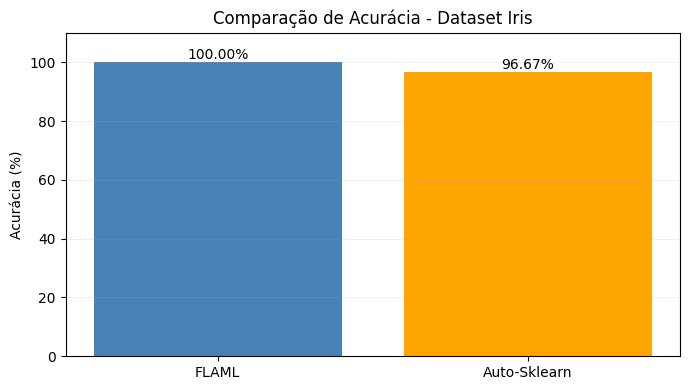

In [29]:

# Importa as bibliotecas necessárias.
import pandas as pd
import matplotlib.pyplot as plt
import json

# Carrega os resultados do Auto-Sklearn.
with open("/content/resultado_autosklearn.json", "r") as arquivo:
    resultado_auto = json.load(arquivo)

# Organiza os resultados dos dois frameworks.
resultados = pd.DataFrame({
    "Framework": ["FLAML", "Auto-Sklearn"],
    "Acurácia (%)": [
        acuracia_flaml * 100,
        resultado_auto["acuracia"] * 100
    ],
    "Tempo (s)": [
        tempo_flaml,
        resultado_auto["tempo"]
    ]
})

# Mostra a tabela comparativa.
print("=" * 45)
print("COMPARAÇÃO DOS FRAMEWORKS")
print("=" * 45)
print(resultados.to_string(index=False))
print("=" * 45)

# Cria o gráfico de acurácia.
plt.figure(figsize=(7, 4))

barras = plt.bar(
    resultados["Framework"],
    resultados["Acurácia (%)"],
    color=["steelblue", "orange"]
)

# Mostra os valores acima das barras.
for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{barra.get_height():.2f}%",
        ha="center"
    )

plt.title("Comparação de Acurácia - Dataset Iris")
plt.ylabel("Acurácia (%)")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# Etapa 12 — Comparação do tempo de execução
Explicação: Comparamos visualmente o tempo utilizado por cada framework para verificar qual realizou o treinamento mais rapidamente.

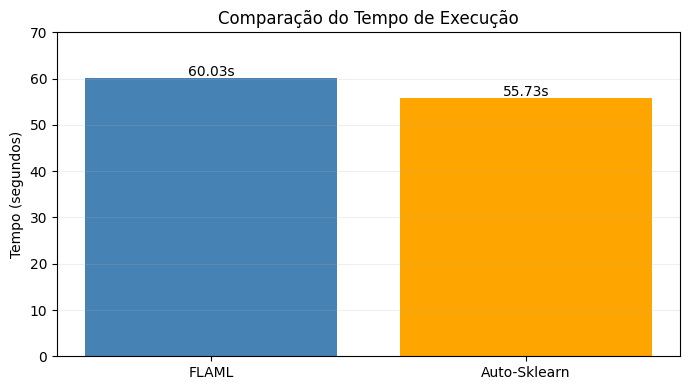

In [30]:

# Cria o gráfico de tempo de execução.
plt.figure(figsize=(7, 4))

barras = plt.bar(
    resultados["Framework"],
    resultados["Tempo (s)"],
    color=["steelblue", "orange"]
)

# Mostra o tempo acima das barras.
for barra in barras:
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        f"{barra.get_height():.2f}s",
        ha="center"
    )

plt.title("Comparação do Tempo de Execução")
plt.ylabel("Tempo (segundos)")
plt.ylim(0, 70)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


# Etapa 13 — Verificação dos recursos computacionais
Explicação: Nesta etapa, verificamos a memória RAM e o uso da CPU no ambiente do Google Colab para complementar a análise do custo computacional.

In [31]:

# Importa a biblioteca necessária.
import psutil

# Consulta os recursos do ambiente.
memoria = psutil.virtual_memory()
cpu = psutil.cpu_percent(interval=1)

# Mostra os resultados.
print("=" * 45)
print("RECURSOS COMPUTACIONAIS")
print("=" * 45)

print(f"Uso da CPU: {cpu:.1f}%")
print(f"Memória total: {memoria.total / (1024**3):.2f} GB")
print(f"Memória utilizada: {memoria.used / (1024**3):.2f} GB")
print(f"Uso da memória: {memoria.percent:.1f}%")

print("=" * 45)


RECURSOS COMPUTACIONAIS
Uso da CPU: 54.2%
Memória total: 12.67 GB
Memória utilizada: 1.55 GB
Uso da memória: 15.1%


# Relatório Final — Comparação entre FLAML e Auto-Sklearn

**1. Desempenho:** Para comparar os frameworks FLAML e Auto-Sklearn, utilizamos o dataset Iris, com 150 amostras divididas em 80% para treinamento e 20% para teste, usando estratificação e `random_state=42`. Ambos receberam um orçamento de busca de 60 segundos. O FLAML apresentou a melhor acurácia, alcançando **100%**, com 30 classificações corretas. Já o Auto-Sklearn obteve **96,67%**, acertando 29 das 30 amostras. Portanto, o FLAML teve melhor desempenho na classificação, embora a diferença tenha sido de apenas uma amostra.

**2. Custo Computacional:** O FLAML levou **60,03 segundos** para realizar o treinamento, enquanto o Auto-Sklearn levou **55,73 segundos**, sendo aproximadamente **4,30 segundos mais rápido**. Também verificamos os recursos do Google Colab, que apresentou 54,2% de utilização da CPU e 1,55 GB de memória RAM utilizada no momento da consulta. Entretanto, esses valores representam o ambiente geral, e não o consumo individual dos frameworks. Dessa forma, o Auto-Sklearn apresentou menor tempo de execução neste teste, mas não foi possível determinar qual ferramenta consumiu menos CPU ou memória durante o treinamento.

**3. Interpretabilidade e Pipelines:** O FLAML selecionou o algoritmo LRL1, baseado em regressão logística com regularização L1, que possui uma estrutura relativamente simples e facilita a interpretação. Já o Auto-Sklearn selecionou um conjunto de **14 modelos**, incluindo Random Forest, SVM, árvores de decisão e redes neurais. Essa combinação apresenta maior variedade de algoritmos, mas também torna a análise das previsões mais complexa. Concluímos que o FLAML facilitou a inspeção do modelo e apresentou maior acurácia, enquanto o Auto-Sklearn teve menor tempo de execução e utilizou uma combinação mais diversificada de modelos.